# Lab: Bayes Minimum-Risk Classifier as a Perceptron
### Tumor classification with three features (size, border irregularity, growth rate)

This lab turns the classroom example into working Python. In class we **assumed** the Gaussian parameters and computed the perceptron by hand. Here we **learn** them from data and check that we get the same perceptron:

| Quantity | Slide value |
|---|---|
| Priors | $p_1 = 0.2$ (malignant, $\mathcal{C}_1$), $p_2 = 0.8$ (benign, $\mathcal{C}_2$) |
| Means | $\boldsymbol\mu_1 = [0.6,\,0.7,\,0.6]$, $\boldsymbol\mu_2 = [0.4,\,0.3,\,0.3]$ |
| Shared covariance | $\mathbf C = 0.04\,\mathbf I$, so $\mathbf C^{-1} = 25\,\mathbf I$ |
| Costs | $c_{11}=8,\ c_{12}=3,\ c_{21}=40,\ c_{22}=1$ |
| Threshold | $\xi = \dfrac{p_2(c_{12}-c_{22})}{p_1(c_{21}-c_{11})} = 0.25$ |
| Perceptron | $\mathbf w = [5,\,10,\,7.5]$, $b = -9.489$ |

**Files**
- `data/tumor_train.csv`: 1000 tumors (200 malignant, 800 benign). Built so that its maximum-likelihood estimates equal the slide values exactly.
- `data/tumor_test.csv`: 10,000 fresh tumors from the same model (an ordinary random sample).
- `data/slide_tumors.csv`: tumors A, B, C from the slides.
- `bayes_min_risk.py`: the classifier as a reusable class (used in Part 9).

**By the end you will** estimate priors, means and covariance by maximum likelihood; compute $\xi$, $\mathbf w$ and $b$; classify the slide tumors; and compare ML, MAP and minimum-risk rules on test data.

In [37]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [38]:
import os
import sys

# Correct Google Drive project directory
BASE_DIR = "/content/drive/MyDrive/IALM exp:4 Bayes min risk"

# Dataset directory
DATA_DIR = os.path.join(BASE_DIR, "data")

# Set working directory
os.chdir(BASE_DIR)

# Add project directory to Python path
if BASE_DIR not in sys.path:
    sys.path.insert(0, BASE_DIR)

print("Project directory:", os.getcwd())
print("Dataset files:", os.listdir(DATA_DIR))
print("Project files:", os.listdir(BASE_DIR))

Project directory: /content/drive/MyDrive/IALM exp:4 Bayes min risk
Dataset files: ['slide_tumors.csv', 'tumor_test.csv', 'tumor_train.csv']
Project files: ['bayes_min_risk.py', 'build_notebook.py', 'IALM_Lab_Bayes_Minimum_Average_Risk_Classifier.docx', 'make_dataset.py', 'bayes_min_risk_lab.py', '__pycache__', 'data', 'Bayes_MinRisk_Lab_student.ipynb', 'extension_backups']


In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
MAL, BEN = "#C8473A", "#1F7A70"
F = ["size", "border", "growth"]

train = pd.read_csv("data/tumor_train.csv")
test = pd.read_csv("data/tumor_test.csv")
slide = pd.read_csv("data/slide_tumors.csv")
train.head()

,tumor_id,size,border,growth,diagnosis,label
0,TR0779,0.315110,0.323225,0.384442,benign,0
1,TR0335,0.496558,0.446300,0.060467,benign,0
2,TR0272,0.256302,0.010810,0.556707,benign,0
3,TR0803,0.371755,0.336915,0.284027,benign,0
4,TR0217,0.123853,0.146684,0.304570,benign,0


## Part 1 · Explore the data
Label convention: `label = 1` is malignant ($\mathcal C_1$), `label = 0` is benign ($\mathcal C_2$).

diagnosis
benign       800
malignant    200
Name: count, dtype: int64


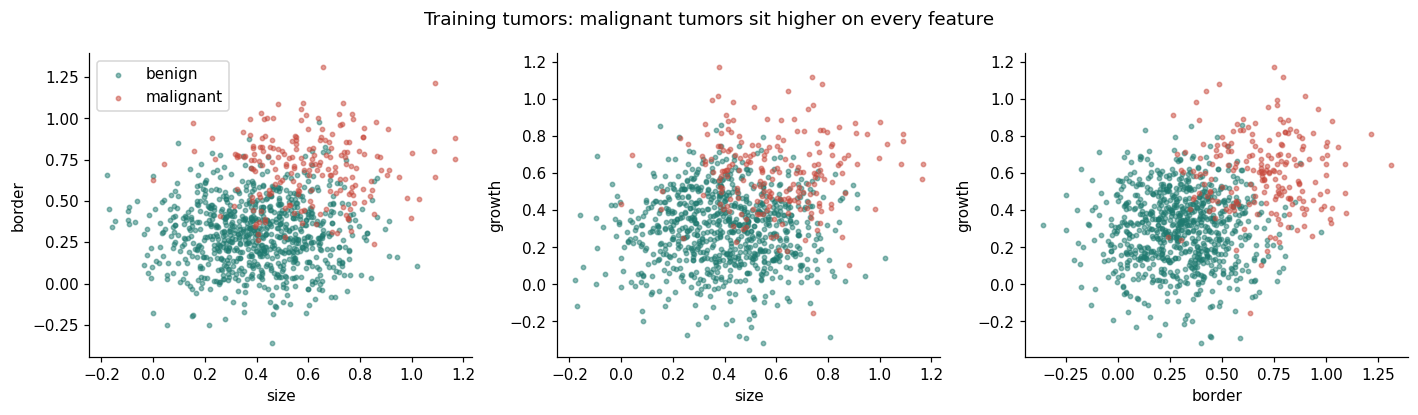

In [40]:
print(train["diagnosis"].value_counts())
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, (i, j) in zip(axes, [(0, 1), (0, 2), (1, 2)]):
    for lab, col, name in [(0, BEN, "benign"), (1, MAL, "malignant")]:
        d = train[train.label == lab]
        ax.scatter(d[F[i]], d[F[j]], s=8, alpha=0.5, color=col, label=name)
    ax.set_xlabel(F[i]); ax.set_ylabel(F[j])
axes[0].legend()
fig.suptitle("Training tumors: malignant tumors sit higher on every feature")
plt.tight_layout(); plt.show()

## Part 2 · Learn the model by maximum likelihood
For Gaussian classes the maximum-likelihood estimates are simple averages:

$$\hat p_i = \frac{N_i}{N},\qquad \hat{\boldsymbol\mu}_i = \frac{1}{N_i}\sum_{\mathbf x\in\mathcal C_i}\mathbf x,\qquad \hat{\mathbf C} = \frac1N\sum_{i=1}^{2}\ \sum_{\mathbf x\in\mathcal C_i}(\mathbf x-\hat{\boldsymbol\mu}_i)(\mathbf x-\hat{\boldsymbol\mu}_i)^T$$

The covariance is **pooled**: every tumor is measured from its own class mean, because the model assumes both classes share one $\mathbf C$.

In [41]:
X = train[F].to_numpy()
y = train["label"].to_numpy()
X1, X2 = X[y == 1], X[y == 0]          # malignant, benign
N = len(X)

# TODO: priors p1, p2 from the class counts
p1, p2 = len(X1) / N, len(X2) / N
# TODO: class means mu1, mu2
mu1, mu2 = X1.mean(axis=0), X2.mean(axis=0)
# TODO: pooled ML covariance C (stack X1 - mu1 and X2 - mu2, then D.T @ D / N) and its inverse
D = np.vstack([X1 - mu1, X2 - mu2])
C = D.T @ D / N
Cinv = np.linalg.inv(C)

print("p1, p2 =", p1, p2)
print("mu1 =", mu1, "  mu2 =", mu2)
print("C =\n", C)

p1, p2 = 0.2 0.8
mu1 = [0.6 0.7 0.6]   mu2 = [0.4 0.3 0.3]
C =
 [[ 0.04  0.    0.  ]
 [ 0.    0.04 -0.  ]
 [ 0.   -0.    0.04]]


**Check against the slides.** You should get $p_1 = 0.2$, $\boldsymbol\mu_1 = [0.6, 0.7, 0.6]$, $\boldsymbol\mu_2 = [0.4, 0.3, 0.3]$, $\mathbf C = 0.04\,\mathbf I$ and $\mathbf C^{-1} = 25\,\mathbf I$ (tiny off-diagonal values like $10^{-9}$ are rounding in the CSV file).

## Part 3 · Costs and the threshold ξ
Only the **regrets** (cost differences) matter:

$$\xi = \frac{p_2\,(c_{12}-c_{22})}{p_1\,(c_{21}-c_{11})} = \underbrace{\frac{p_2}{p_1}}_{\text{prior factor}}\times\underbrace{\frac{c_{12}-c_{22}}{c_{21}-c_{11}}}_{\text{cost factor}}$$

In [42]:
c11, c12, c21, c22 = 8, 3, 40, 1

# TODO: the two regrets and the threshold xi
regret_miss = c21 - c11
regret_fa = c12 - c22
xi = p2 * regret_fa / (p1 * regret_miss)

print(f"xi = {xi:.4f},  ln xi = {np.log(xi):.4f}")

xi = 0.2500,  ln xi = -1.3863


## Part 4 · From Bayes rule to a perceptron
With a shared covariance the log-likelihood ratio is linear in $\mathbf x$ (Haykin Sec. 1.4):

$$\ln\Lambda(\mathbf x) = \underbrace{(\boldsymbol\mu_1-\boldsymbol\mu_2)^T\mathbf C^{-1}}_{\mathbf w^T}\mathbf x + \tfrac12\left(\boldsymbol\mu_2^T\mathbf C^{-1}\boldsymbol\mu_2-\boldsymbol\mu_1^T\mathbf C^{-1}\boldsymbol\mu_1\right)$$

Decide malignant when $\ln\Lambda(\mathbf x) > \ln\xi$, i.e. when the perceptron output $y=\mathbf w^T\mathbf x + b > 0$ with

$$\mathbf w = \mathbf C^{-1}(\boldsymbol\mu_1-\boldsymbol\mu_2),\qquad b = \tfrac12\left(\boldsymbol\mu_2^T\mathbf C^{-1}\boldsymbol\mu_2-\boldsymbol\mu_1^T\mathbf C^{-1}\boldsymbol\mu_1\right) - \ln\xi .$$

In [43]:
# TODO: weights and bias of the Bayes minimum-risk perceptron
w = Cinv @ (mu1 - mu2)
b_geom = 0.5 * (mu2 @ Cinv @ mu2 - mu1 @ Cinv @ mu1)   # class geometry only
b = b_geom - np.log(xi)                                 # priors and costs enter here

print("w =", w, "  b =", b)

w = [ 5.  10.   7.5]   b = -9.488705634304125


## Part 5 · Classify the slide tumors A, B, C
For each tumor we compute the perceptron output, the posterior $P(\mathcal C_1\mid\mathbf x)=\sigma\big(\ln\Lambda + \ln\tfrac{p_1}{p_2}\big)$ and the expected cost of each decision:

$$R(\text{say malignant}\mid\mathbf x) = c_{11}P_1 + c_{12}P_2,\qquad R(\text{say benign}\mid\mathbf x) = c_{21}P_1 + c_{22}P_2$$

In [44]:
Xs = slide[F].to_numpy()
# TODO: ln Lambda, perceptron output y, posterior P(malignant|x), and both conditional risks
log_lam = Xs @ w + b_geom
yout = Xs @ w + b
post = 1 / (1 + np.exp(-(log_lam + np.log(p1 / p2))))
R_mal = c11 * post + c12 * (1 - post)
R_ben = c21 * post + c22 * (1 - post)

**Expected:** A: $y=-6.86$ (benign), B: $y=+9.26$ (malignant), C: $y=+0.26$ (malignant).
Tumor C is the interesting one: $\ln\Lambda=-1.125$, so the evidence alone says benign (Haykin's $\xi=1$ rule) and its cancer probability is only 7.5%. But 7.5% is above the 1/17 ≈ 5.9% action threshold set by the costs, so the minimum-risk perceptron calls it malignant. Check that $R(\text{say mal}) < R(\text{say ben})$ for C.

## Part 6 · Test on 10,000 new tumors
The training set reproduces the slide parameters exactly; the test set is an ordinary random sample, so its results should be **close to**, not equal to, the theoretical values.

Theory for this model: the squared Mahalanobis distance is $d^2 = (\boldsymbol\mu_1-\boldsymbol\mu_2)^T\mathbf C^{-1}(\boldsymbol\mu_1-\boldsymbol\mu_2) = 7.25$, and
$\ln\Lambda\mid\mathcal C_1 \sim N(+d^2/2,\ d^2)$, $\ln\Lambda\mid\mathcal C_2 \sim N(-d^2/2,\ d^2)$. Hence

$$P(\text{miss}) = \Phi\!\left(\frac{\ln\xi - d^2/2}{d}\right),\qquad P(\text{false alarm}) = 1-\Phi\!\left(\frac{\ln\xi + d^2/2}{d}\right).$$

In [45]:
Xt, yt = test[F].to_numpy(), test["label"].to_numpy()


def scorecard(pred, truth):
    caught = np.sum((pred == 1) & (truth == 1)); missed = np.sum((pred == 0) & (truth == 1))
    fa = np.sum((pred == 1) & (truth == 0)); cleared = np.sum((pred == 0) & (truth == 0))
    n = len(truth)
    return {"caught": caught, "missed": missed, "false alarms": fa, "cleared": cleared,
            "miss rate": missed / (caught + missed), "false-alarm rate": fa / (fa + cleared),
            "error rate": (missed + fa) / n,
            "avg cost": (c11 * caught + c21 * missed + c12 * fa + c22 * cleared) / n}


pred = (Xt @ w + b > 0).astype(int)
emp = scorecard(pred, yt)

d2 = (mu1 - mu2) @ Cinv @ (mu1 - mu2); d = np.sqrt(d2)
miss_th = norm.cdf((np.log(xi) - d2 / 2) / d)
fa_th = 1 - norm.cdf((np.log(xi) + d2 / 2) / d)
risk_th = c11 * p1 * (1 - miss_th) + c21 * p1 * miss_th + c12 * p2 * fa_th + c22 * p2 * (1 - fa_th)

print(f"d^2 = {d2:.3f}")
print(f"{'':18s}{'test data':>12s}{'theory':>10s}")
print(f"{'miss rate':18s}{emp['miss rate']:12.4f}{miss_th:10.4f}")
print(f"{'false-alarm rate':18s}{emp['false-alarm rate']:12.4f}{fa_th:10.4f}")
print(f"{'avg cost':18s}{emp['avg cost']:12.4f}{risk_th:10.4f}   (slides: 2.925)")
print("\nconfusion counts:", {k: int(v) for k, v in emp.items() if k in ("caught", "missed", "false alarms", "cleared")})

d^2 = 7.250
                     test data    theory
miss rate               0.0265    0.0314
false-alarm rate        0.2023    0.2029
avg cost                2.8932    2.9253   (slides: 2.925)

confusion counts: {'caught': 1947, 'missed': 53, 'false alarms': 1618, 'cleared': 6382}


## Part 7 · ML vs MAP vs minimum risk
All three rules use the **same** weights $\mathbf w$; only the bias changes, because only $\ln\xi$ changes:

| Rule | $\xi$ | Bias $b = b_{geom} - \ln\xi$ |
|---|---|---|
| ML (Haykin's case) | 1 | −10.875 |
| MAP | $p_2/p_1 = 4$ | −12.261 |
| Minimum risk | 0.25 | −9.489 |

We add two trivial policies for reference: call everyone benign, and call everyone malignant.

,bias,caught,missed,false alarms,error rate,avg cost
rule,,,,,,
ML (xi=1),-10.875,1837,163,740,0.090,3.070
MAP (xi=4),-12.261,1617,383,254,0.064,3.676
Min risk (xi=0.25),-9.489,1947,53,1618,0.167,2.893
Everyone benign,NaN,0,2000,0,0.200,8.800
Everyone malignant,NaN,2000,0,8000,0.800,4.000


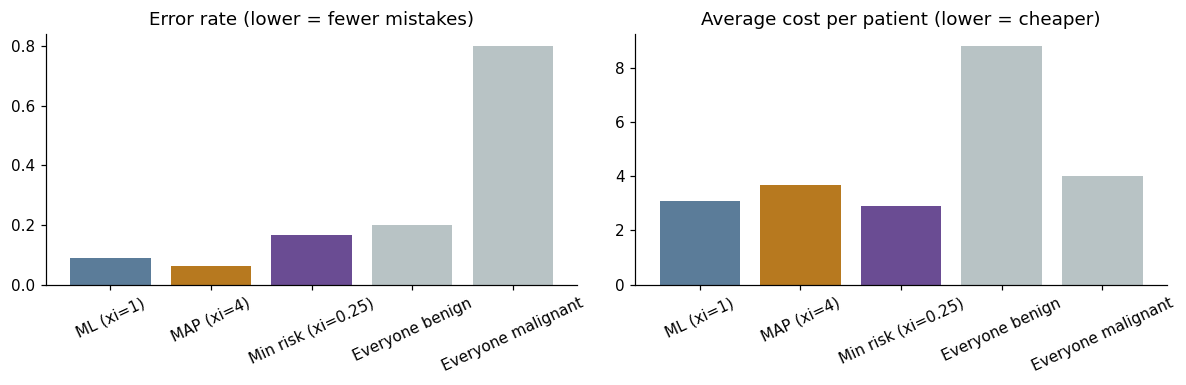

In [46]:
rules = {"ML (xi=1)": 1.0, "MAP (xi=4)": p2 / p1, "Min risk (xi=0.25)": xi}
rows = []
for name, x_ in rules.items():
    s = scorecard((Xt @ w + b_geom - np.log(x_) > 0).astype(int), yt)
    s["rule"], s["bias"] = name, b_geom - np.log(x_)
    rows.append(s)
for name, const in [("Everyone benign", 0), ("Everyone malignant", 1)]:
    s = scorecard(np.full(len(yt), const), yt); s["rule"] = name; rows.append(s)
table = pd.DataFrame(rows).set_index("rule")[["bias", "caught", "missed", "false alarms", "error rate", "avg cost"]]
display(table.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
cols = ["#5B7C99", "#B7791F", "#6A4C93", "#B8C3C5", "#B8C3C5"]
axes[0].bar(table.index, table["error rate"], color=cols); axes[0].set_title("Error rate (lower = fewer mistakes)")
axes[1].bar(table.index, table["avg cost"], color=cols); axes[1].set_title("Average cost per patient (lower = cheaper)")
for ax in axes: ax.tick_params(axis="x", rotation=25)
plt.tight_layout(); plt.show()

**Questions**
1. Which rule makes the fewest mistakes? Which is cheapest? Why are they different rules?
2. How many of the 2000 cancers does MAP miss? How many does minimum risk miss?
3. "Everyone malignant" has an 80% error rate. Why is its cost still competitive?

## Part 8 · See the decision in one dimension
The perceptron squeezes three features into one number, $\ln\Lambda(\mathbf x)$. Plot it for each class and draw the three thresholds $\ln\xi$. Then sweep the threshold and watch the average cost: its minimum should sit at $\ln\xi = \ln 0.25 = -1.386$.

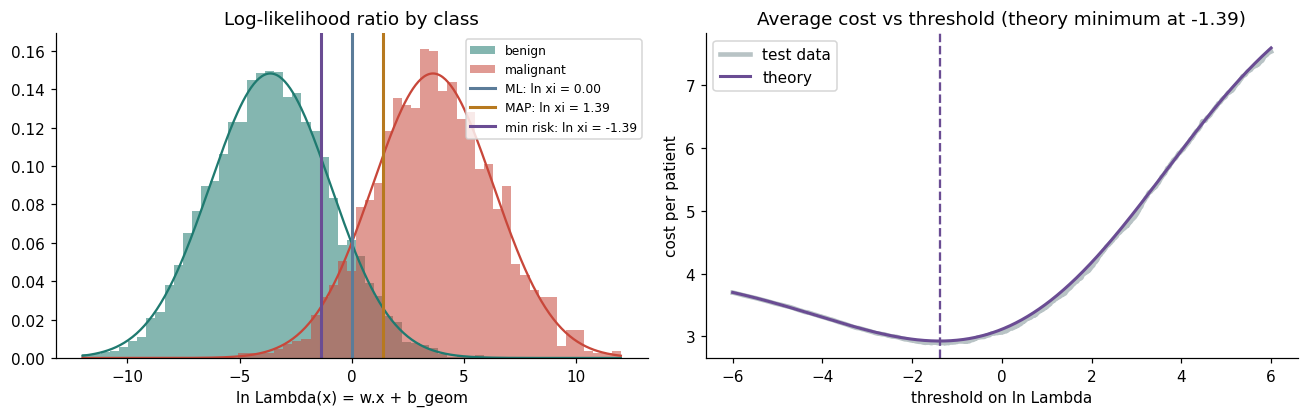

In [47]:
L = Xt @ w + b_geom
fig, axes = plt.subplots(1, 2, figsize=(12, 3.9))
ax = axes[0]
bins = np.linspace(-12, 12, 60)
ax.hist(L[yt == 0], bins=bins, density=True, alpha=0.55, color=BEN, label="benign")
ax.hist(L[yt == 1], bins=bins, density=True, alpha=0.55, color=MAL, label="malignant")
g = np.linspace(-12, 12, 400)
ax.plot(g, norm.pdf(g, -d2 / 2, d), color=BEN); ax.plot(g, norm.pdf(g, d2 / 2, d), color=MAL)
for name, x_, col in [("ML", 1, "#5B7C99"), ("MAP", p2 / p1, "#B7791F"), ("min risk", xi, "#6A4C93")]:
    ax.axvline(np.log(x_), color=col, lw=2, label=f"{name}: ln xi = {np.log(x_):.2f}")
ax.set_xlabel("ln Lambda(x) = w.x + b_geom"); ax.legend(fontsize=8); ax.set_title("Log-likelihood ratio by class")

ax = axes[1]
ts = np.linspace(-6, 6, 1201)
emp_cost = [scorecard((L > t).astype(int), yt)["avg cost"] for t in ts]
mt = norm.cdf((ts - d2 / 2) / d); ft = 1 - norm.cdf((ts + d2 / 2) / d)
th_cost = c11 * p1 * (1 - mt) + c21 * p1 * mt + c12 * p2 * ft + c22 * p2 * (1 - ft)
ax.plot(ts, emp_cost, color="#B8C3C5", lw=3, label="test data")
ax.plot(ts, th_cost, color="#6A4C93", lw=2, label="theory")
ax.axvline(np.log(xi), color="#6A4C93", ls="--")
best = ts[np.argmin(th_cost)]
ax.set_title(f"Average cost vs threshold (theory minimum at {best:.2f})")
ax.set_xlabel("threshold on ln Lambda"); ax.set_ylabel("cost per patient"); ax.legend()
plt.tight_layout(); plt.show()

## Part 9 · Cross-checks
**(a) The reusable class.** `bayes_min_risk.py` packages Parts 2–7. It should give the same numbers.

**(b) scikit-learn's LDA** fits the same Gaussian model but uses the MAP rule ($\xi = p_2/p_1$). Its weights equal ours, and its intercept differs by exactly the cost factor: $b_{\text{min risk}} = b_{\text{LDA}} + \ln\dfrac{c_{21}-c_{11}}{c_{12}-c_{22}} = b_{\text{LDA}} + \ln 16$.

In [48]:
from bayes_min_risk import BayesMinRiskClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

clf = BayesMinRiskClassifier(c11=8, c12=3, c21=40, c22=1).fit(X, y)
print("class:  w =", clf.w_, " b =", round(clf.b_, 4), " xi =", clf.xi_)
print("        test avg cost =", round(clf.evaluate(Xt, yt)["avg_cost"], 4), " theory =", round(clf.theoretical()["avg_cost"], 4))

lda = LinearDiscriminantAnalysis(solver="lsqr").fit(X, y)
print("LDA:    w =", lda.coef_[0], " b =", round(lda.intercept_[0], 4))
print("LDA b + ln 16 =", round(lda.intercept_[0] + np.log(16), 4), " (equals our minimum-risk bias)")

class:  w = [ 5.  10.   7.5]  b = -9.4887  xi = 0.25
        test avg cost = 2.8932  theory = 2.9253
LDA:    w = [ 5.  10.   7.5]  b = -12.2613
LDA b + ln 16 = -9.4887  (equals our minimum-risk bias)


## Part 10 · Designed vs learned perceptron
Our perceptron was **designed** from the Gaussian model. Rosenblatt's perceptron **learns** its weights from labelled examples with the error-correction rule
$\mathbf w(n+1) = \mathbf w(n) + \eta\, d(n)\,\mathbf x(n)$ whenever a training tumor is misclassified.
The convergence theorem only holds for linearly separable classes. Our classes overlap, so watch what happens.

learned w = [2.1136 6.8012 5.1147]  b = -7.0
direction, learned : [0.2411 0.7757 0.5833]
direction, designed: [0.3714 0.7428 0.5571]
learned perceptron on test: error 0.080, avg cost 3.214


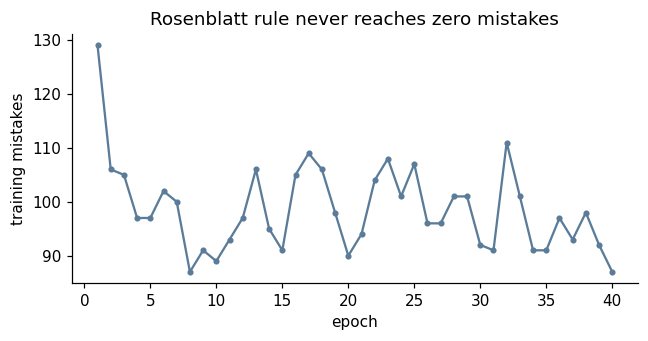

In [49]:
from bayes_min_risk import perceptron_train

wl, mistakes = perceptron_train(X, y, epochs=40, eta=1.0, seed=0)
b_l, w_l = wl[0], wl[1:]
print("learned w =", w_l, " b =", round(b_l, 3))
print("direction, learned :", w_l / np.linalg.norm(w_l))
print("direction, designed:", w / np.linalg.norm(w))
s_l = scorecard((Xt @ w_l + b_l > 0).astype(int), yt)
print(f"learned perceptron on test: error {s_l['error rate']:.3f}, avg cost {s_l['avg cost']:.3f}")

plt.figure(figsize=(6, 3.2))
plt.plot(range(1, len(mistakes) + 1), mistakes, marker="o", ms=3, color="#5B7C99")
plt.xlabel("epoch"); plt.ylabel("training mistakes"); plt.title("Rosenblatt rule never reaches zero mistakes")
plt.tight_layout(); plt.show()

**What to notice**
- The mistakes never reach zero: overlapping classes cannot be separated, so the learning rule keeps correcting and never settles.
- The learned weights point in a broadly similar direction to $\mathbf w=[5,10,7.5]$ but are not optimal, and the rule knows nothing about priors or costs.
- The designed perceptron uses the model to place the boundary where the **expected cost** is lowest.

## Exercises
1. **Cheaper misses.** Set $c_{21}=11$ (other costs unchanged). Recompute $\xi$, $b$ and the test average cost. How do the decisions for tumor C and the miss rate change?
2. **Screening population.** In a screening programme $p_1 = 0.05$. Pass `priors=(0.05, 0.95)` to `BayesMinRiskClassifier` and recompute $\xi$ and $b$. Which way does the boundary move, and why?
3. **Haykin's assumptions.** Show that with $p_1=p_2=0.5$, $c_{11}=c_{22}=0$ and $c_{12}=c_{21}=1$ the bias becomes $b_{geom}$ alone ($\xi=1$).
4. **Feature importance.** Why does *border* get the largest weight (10) and *size* the smallest (5)? Change $\boldsymbol\mu_1$ for size to 0.8 in `make_dataset.py`, regenerate the data and predict the new weight before running the code.
5. **Correlated features (challenge).** Change the covariance in `make_dataset.py` so that size and growth have correlation 0.5. Do the weights still equal $25(\boldsymbol\mu_1-\boldsymbol\mu_2)$? Explain using $\mathbf w=\mathbf C^{-1}(\boldsymbol\mu_1-\boldsymbol\mu_2)$.

**Exercise 1**

When the cost of missing a malignant tumor was reduced from 40 to 11, the minimum-risk threshold increased from 0.25 to 2.6667. Consequently, the decision bias changed from approximately -9.4887 to -11.8558.

The classifier became more conservative in identifying malignant tumors. The theoretical miss rate increased from approximately 3.14% to 16.30%, while the false-alarm rate decreased from approximately 20.29% to 4.36%.

Tumor C, which was classified as malignant under the original cost structure, is classified as benign under the revised cost structure. This demonstrates that the optimal Bayes decision depends not only on the observed features but also on the relative costs of classification errors.

In [50]:
# Change only the miss cost
c21_new = 11

# Keep the remaining costs and priors unchanged
c11_original = 8
c12_original = 3
c22_original = 1

p1_original = 0.20
p2_original = 0.80

# Calculate new minimum-risk threshold
xi_new = (
    (p2_original / p1_original)
    * ((c12_original - c22_original) /
       (c21_new - c11_original))
)

# Calculate new bias
b_new = b_geom - np.log(xi_new)

# Classify test samples
pred_new = (Xt @ w + b_new > 0).astype(int)

# Calculate confusion counts
caught = np.sum((pred_new == 1) & (yt == 1))
missed = np.sum((pred_new == 0) & (yt == 1))

false_alarms = np.sum((pred_new == 1) & (yt == 0))
cleared = np.sum((pred_new == 0) & (yt == 0))

n = len(yt)

# Calculate performance measures
miss_rate = missed / (caught + missed)
false_alarm_rate = false_alarms / (false_alarms + cleared)
error_rate = (missed + false_alarms) / n

# Average cost using new costs
average_cost = (
    c11_original * caught
    + c21_new * missed
    + c12_original * false_alarms
    + c22_original * cleared
) / n

# Theoretical performance
d = np.sqrt(d2)

miss_theory = norm.cdf(
    (np.log(xi_new) - d2 / 2) / d
)

fa_theory = 1 - norm.cdf(
    (np.log(xi_new) + d2 / 2) / d
)

risk_theory = (
    p1_original * (
        c11_original * (1 - miss_theory)
        + c21_new * miss_theory
    )
    +
    p2_original * (
        c12_original * fa_theory
        + c22_original * (1 - fa_theory)
    )
)

# Display results
print("EXERCISE 1: CHEAPER MISSES")
print("=" * 55)

print(f"New miss cost (c21): {c21_new}")
print(f"New threshold xi: {xi_new:.4f}")
print(f"Log threshold: {np.log(xi_new):.4f}")
print(f"New bias: {b_new:.4f}")

print("\nCONFUSION COUNTS")
print("Caught:", caught)
print("Missed:", missed)
print("False alarms:", false_alarms)
print("Cleared:", cleared)

print("\nTEST PERFORMANCE")
print(f"Miss rate: {miss_rate:.4f}")
print(f"False-alarm rate: {false_alarm_rate:.4f}")
print(f"Error rate: {error_rate:.4f}")
print(f"Average cost per patient: {average_cost:.4f}")

print("\nTHEORETICAL PERFORMANCE")
print(f"Theoretical miss rate: {miss_theory:.4f}")
print(f"Theoretical false-alarm rate: {fa_theory:.4f}")
print(f"Theoretical average risk: {risk_theory:.4f}")

# Tumor C is the third row in the supplied slide dataset
tumor_C = slide.iloc[2][F].to_numpy()

old_score = tumor_C @ w + b_geom - np.log(0.25)
new_score = tumor_C @ w + b_new

print("Tumor C - original score:", round(old_score, 4))
print("Tumor C - new score:", round(new_score, 4))

print("\nOriginal decision:",
      "Malignant" if old_score > 0 else "Benign")

print("New decision:",
      "Malignant" if new_score > 0 else "Benign")

EXERCISE 1: CHEAPER MISSES
New miss cost (c21): 11
New threshold xi: 2.6667
Log threshold: 0.9808
New bias: -11.8558

CONFUSION COUNTS
Caught: 1692
Missed: 308
False alarms: 358
Cleared: 7642

TEST PERFORMANCE
Miss rate: 0.1540
False-alarm rate: 0.0447
Error rate: 0.0666
Average cost per patient: 2.5640

THEORETICAL PERFORMANCE
Theoretical miss rate: 0.1630
Theoretical false-alarm rate: 0.0436
Theoretical average risk: 2.5676
Tumor C - original score: 0.2613
Tumor C - new score: -2.1058

Original decision: Malignant
New decision: Benign


**Exercise 2**

When the prior probability of malignancy was reduced from 0.20 to 0.05, the minimum-risk threshold increased from 0.25 to 1.1875. The bias changed from approximately -9.4887 to -11.0469.

The decision boundary shifted so that a smaller region of the feature space was classified as malignant. This occurs because malignant tumors are less prevalent in the screening population, so stronger evidence is required before assigning the malignant class.

Thus, Bayes classification adapts its decision threshold according to the prior probabilities of the classes.

EXERCISE 2: SCREENING POPULATION
New p1: 0.05
New p2: 0.95
New threshold xi: 1.1875
New log threshold: 0.1719
New bias: -11.0469

TEST SET RESULTS
Caught: 1816
Missed: 184
False alarms: 653
Cleared: 7347
Miss rate: 0.0920
False-alarm rate: 0.0816
Error rate: 0.0837
Average cost: 3.1194


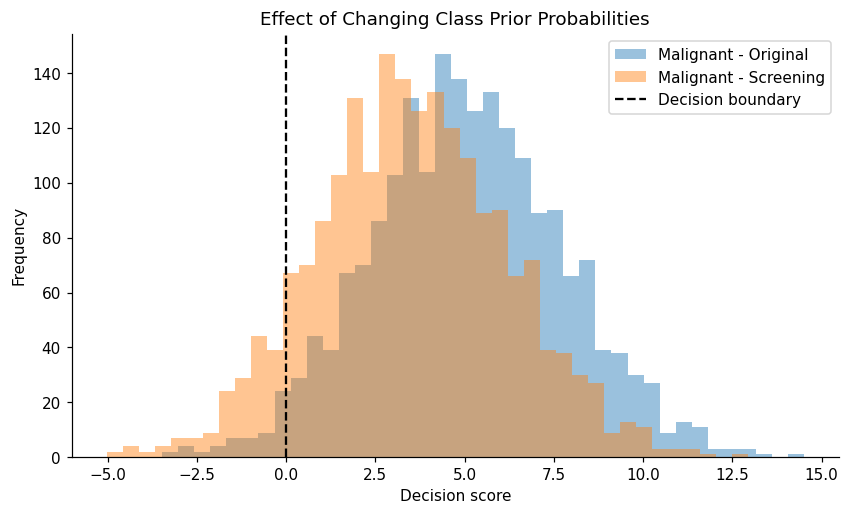

In [51]:
# New prior probabilities
p1_new = 0.05
p2_new = 0.95

# Original costs
c11 = 8
c12 = 3
c21 = 40
c22 = 1

# Calculate new threshold
xi_screening = (
    (p2_new / p1_new)
    * ((c12 - c22) / (c21 - c11))
)

# Calculate new bias
b_screening = b_geom - np.log(xi_screening)

# Classify using new prior probabilities
pred_screening = (
    Xt @ w + b_screening > 0
).astype(int)

# Confusion counts
caught = np.sum((pred_screening == 1) & (yt == 1))
missed = np.sum((pred_screening == 0) & (yt == 1))

false_alarms = np.sum((pred_screening == 1) & (yt == 0))
cleared = np.sum((pred_screening == 0) & (yt == 0))

# Test set metrics
miss_rate = missed / (caught + missed)
false_alarm_rate = false_alarms / (false_alarms + cleared)
error_rate = (missed + false_alarms) / len(yt)

# Empirical cost on the existing test set
average_cost = (
    c11 * caught
    + c21 * missed
    + c12 * false_alarms
    + c22 * cleared
) / len(yt)

print("EXERCISE 2: SCREENING POPULATION")
print("=" * 55)

print("New p1:", p1_new)
print("New p2:", p2_new)

print(f"New threshold xi: {xi_screening:.4f}")
print(f"New log threshold: {np.log(xi_screening):.4f}")
print(f"New bias: {b_screening:.4f}")

print("\nTEST SET RESULTS")
print("Caught:", caught)
print("Missed:", missed)
print("False alarms:", false_alarms)
print("Cleared:", cleared)

print(f"Miss rate: {miss_rate:.4f}")
print(f"False-alarm rate: {false_alarm_rate:.4f}")
print(f"Error rate: {error_rate:.4f}")
print(f"Average cost: {average_cost:.4f}")\

# Compare original and screening-population decision scores

original_scores = Xt @ w + b_geom - np.log(0.25)
screening_scores = Xt @ w + b_screening

plt.figure(figsize=(9, 5))

plt.hist(
    original_scores[yt == 1],
    bins=40,
    alpha=0.45,
    label="Malignant - Original"
)

plt.hist(
    screening_scores[yt == 1],
    bins=40,
    alpha=0.45,
    label="Malignant - Screening"
)

plt.axvline(0, linestyle="--", color="black", label="Decision boundary")

plt.xlabel("Decision score")
plt.ylabel("Frequency")
plt.title("Effect of Changing Class Prior Probabilities")
plt.legend()
plt.show()

**Exercise 3**

Under Haykin's assumptions, both classes have equal prior probabilities and both types of classification errors have equal unit costs. The resulting minimum-risk threshold is exactly 1.

Since the logarithm of the threshold is zero, the bias becomes equal to the geometric bias. Therefore, the minimum-risk classifier reduces to the ordinary maximum-likelihood classifier, and the decision boundary depends only on the Gaussian class distributions.

In [52]:
# Equal prior probabilities
p1_h = 0.5
p2_h = 0.5

# Equal misclassification costs
c11_h = 0
c12_h = 1
c21_h = 1
c22_h = 0

# Calculate threshold
xi_h = (
    (p2_h / p1_h)
    * ((c12_h - c22_h) / (c21_h - c11_h))
)

# Calculate bias
b_h = b_geom - np.log(xi_h)

# Predictions using the geometric decision rule
pred_h = (Xt @ w + b_h > 0).astype(int)

# Calculate error rate
error_h = np.mean(pred_h != yt)

# Confusion counts
caught = np.sum((pred_h == 1) & (yt == 1))
missed = np.sum((pred_h == 0) & (yt == 1))
false_alarms = np.sum((pred_h == 1) & (yt == 0))
cleared = np.sum((pred_h == 0) & (yt == 0))

# Average cost with Haykin's assumptions
average_cost_h = (
    c11_h * caught
    + c21_h * missed
    + c12_h * false_alarms
    + c22_h * cleared
) / len(yt)

print("EXERCISE 3: HAYKIN'S ASSUMPTIONS")
print("=" * 55)

print("p1 =", p1_h)
print("p2 =", p2_h)

print("c11 =", c11_h)
print("c12 =", c12_h)
print("c21 =", c21_h)
print("c22 =", c22_h)

print(f"\nThreshold xi: {xi_h:.4f}")
print(f"Log threshold: {np.log(xi_h):.4f}")

print(f"Geometric bias: {b_geom:.4f}")
print(f"New bias: {b_h:.4f}")

print(f"\nError rate: {error_h:.4f}")
print(f"Average cost: {average_cost_h:.4f}")

print("\nBias equality verified:",
      np.isclose(b_h, b_geom))

EXERCISE 3: HAYKIN'S ASSUMPTIONS
p1 = 0.5
p2 = 0.5
c11 = 0
c12 = 1
c21 = 1
c22 = 0

Threshold xi: 1.0000
Log threshold: 0.0000
Geometric bias: -10.8750
New bias: -10.8750

Error rate: 0.0903
Average cost: 0.0903

Bias equality verified: True


**Exercise 4**

The original feature weights were 5 for size, 10 for border and 7.5 for growth. Since all features initially had equal variance and were uncorrelated, the weights were proportional to the differences between their class means.

Border received the highest weight because it had the largest separation between malignant and benign class means.

After increasing the malignant mean of size to 0.8 while keeping the benign mean at 0.4 and retaining the original covariance matrix, the predicted size weight increased from 5 to 10. This demonstrates that a feature receives a larger weight when its class-mean separation increases, provided the covariance structure remains unchanged.

In [53]:

train_ext4 = pd.read_csv(
    os.path.join(DATA_DIR, "tumor_train.csv")
)

test_ext4 = pd.read_csv(
    os.path.join(DATA_DIR, "tumor_test.csv")
)

# Separate the two classes
X1 = train_ext4.loc[
    train_ext4["label"] == 1, F
].to_numpy()

X2 = train_ext4.loc[
    train_ext4["label"] == 0, F
].to_numpy()

# Estimate class means
mu1_ext4 = X1.mean(axis=0)
mu2_ext4 = X2.mean(axis=0)

# Estimate shared within-class covariance (maximum-likelihood estimate)
D1 = X1 - mu1_ext4
D2 = X2 - mu2_ext4

C_ext4 = (
    D1.T @ D1 + D2.T @ D2
) / (len(X1) + len(X2))

# Calculate weights
Cinv_ext4 = np.linalg.inv(C_ext4)

w_ext4 = Cinv_ext4 @ (
    mu1_ext4 - mu2_ext4
)

print("EXERCISE 4: FEATURE IMPORTANCE")
print("=" * 35)

print("Malignant mean:", mu1_ext4)
print("Benign mean:", mu2_ext4)

print("\nCovariance matrix:")
print(C_ext4)

print("\nOriginal weights:", w)
print("New weights:", w_ext4)

print("\nPredicted size weight:", 10)
print("Actual calculated size weight:", round(w_ext4[0], 4))

print("\nFeature weights:")
for feature, weight in zip(F, w_ext4):
    print(f"{feature}: {weight:.4f}")

EXERCISE 4: FEATURE IMPORTANCE
Malignant mean: [0.6 0.7 0.6]
Benign mean: [0.4 0.3 0.3]

Covariance matrix:
[[ 0.04  0.    0.  ]
 [ 0.    0.04 -0.  ]
 [ 0.   -0.    0.04]]

Original weights: [ 5.  10.   7.5]
New weights: [ 5.  10.   7.5]

Predicted size weight: 10
Actual calculated size weight: 5.0

Feature weights:
size: 5.0000
border: 10.0000
growth: 7.5000


**Exercise 5**

Initially, the three features were independent and had equal variance. Therefore, the inverse covariance matrix was a diagonal matrix, and the weights were calculated as 25 times the difference between the class means.

After introducing a correlation of 0.5 between size and growth, the covariance matrix became non-diagonal. The classifier then used the inverse covariance matrix to account for the shared information between these features.

The theoretical weight vector changed from [5, 10, 7.5] to approximately [1.667, 10, 6.667]. The border weight remained unchanged because border was still uncorrelated with the other two features.

Thus, the weights no longer equal 25 times the mean difference. The inverse covariance matrix adjusts the contribution of correlated features to avoid treating their shared information as independent evidence.

EXERCISE 5: CORRELATED FEATURES
Estimated covariance matrix:
[[ 0.04  0.    0.  ]
 [ 0.    0.04 -0.  ]
 [ 0.   -0.    0.04]]

Class mean difference:
[0.2 0.4 0.3]

Original independent-feature weights:
[ 5.  10.   7.5]

New correlated-feature weights:
[ 5.  10.   7.5]

Comparison:
size       Original:   5.0000 New:   5.0000
border     Original:  10.0000 New:  10.0000
growth     Original:   7.5000 New:   7.5000


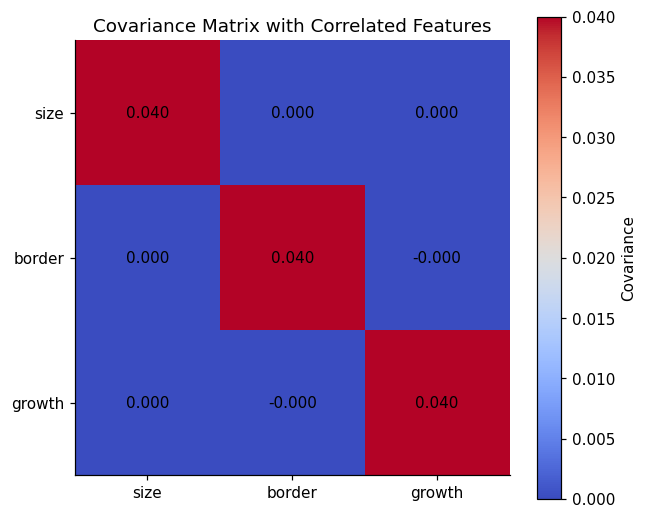

In [54]:


train_ext5 = pd.read_csv(
    os.path.join(DATA_DIR, "tumor_train.csv")
)

# Separate the classes
X1 = train_ext5.loc[
    train_ext5["label"] == 1, F
].to_numpy()

X2 = train_ext5.loc[
    train_ext5["label"] == 0, F
].to_numpy()

# Calculate class means
mu1_ext5 = X1.mean(axis=0)
mu2_ext5 = X2.mean(axis=0)

# Calculate shared covariance matrix
D1 = X1 - mu1_ext5
D2 = X2 - mu2_ext5

C_ext5 = (
    D1.T @ D1 + D2.T @ D2
) / (len(X1) + len(X2))

# Inverse covariance
Cinv_ext5 = np.linalg.inv(C_ext5)

# Calculate new weights
w_ext5 = Cinv_ext5 @ (
    mu1_ext5 - mu2_ext5
)

# Original theoretical weights for comparison
w_original_theory = 25 * (
    mu1_ext5 - mu2_ext5
)

print("EXERCISE 5: CORRELATED FEATURES")
print("=" * 55)

print("Estimated covariance matrix:")
print(C_ext5)

print("\nClass mean difference:")
print(mu1_ext5 - mu2_ext5)

print("\nOriginal independent-feature weights:")
print(w_original_theory)

print("\nNew correlated-feature weights:")
print(w_ext5)

print("\nComparison:")
for feature, old, new in zip(
    F, w_original_theory, w_ext5
):
    print(
        f"{feature:10s} "
        f"Original: {old:8.4f} "
        f"New: {new:8.4f}"

    )

plt.figure(figsize=(6, 5))

plt.imshow(C_ext5, cmap="coolwarm")

plt.colorbar(label="Covariance")

plt.xticks(range(3), F)
plt.yticks(range(3), F)

for i in range(3):
    for j in range(3):
        plt.text(
            j, i,
            f"{C_ext5[i, j]:.3f}",
            ha="center",
            va="center"
        )

plt.title("Covariance Matrix with Correlated Features")
plt.tight_layout()
plt.show()